# Timestral: choose a forecast and create the submission

Run the cells in order. The last section displays all **48 predictions and 95% intervals** and writes `output/BARANIUK_project.csv`.

1. Compare **Timestral**, **LightGBM**, and **seasonal naïve** on the same windows.
2. Check whether removing a weather group helps; carry the chosen inputs into the forecast.
3. Choose weights for a Timestral + seasonal naïve + LightGBM blend on CV, freeze them, inspect the retrospective holdout, then export that three-model blend.

**What was “submitted”?** It was the previous LightGBM candidate: LightGBM on `log(y)`, with 25% seasonal naïve on day 2. The name did not confirm an upload. Here it is called **Previous LGBM candidate**.

**What matters for the assignment?** The ranking uses **hours 25–48**: 30% RMSE rank, 30% MAPE rank, 40% Winkler rank. We use the corresponding weighted metrics relative to naïve as a selection proxy; other students' ranks are unavailable. We also report day 1 and the full horizon.

Timestral is pretrained and is not fitted here. All models use raw historical generation. Rolling CV is shown window by window, followed by the selected blend and all holdout windows.

[Open in Colab](https://colab.research.google.com/github/tbaraniuk/time-series_energy-consumption/blob/main/notebooks/timestral_baseline.ipynb). Select a GPU runtime. Locally, use the project's environment. First use downloads the Timestral weights.

In [12]:
import os
import subprocess
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo = Path('/content/time-series_energy-consumption')
    if not repo.exists():
        subprocess.run(['git', 'clone', '-q',
                        'https://github.com/tbaraniuk/time-series_energy-consumption.git', str(repo)], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm', 'statsforecast',
                    'timestral @ git+https://github.com/mistralai/timestral.git'], check=True)

ROOT = Path.cwd() if (Path.cwd() / 'data/train.csv').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

In [13]:
import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from final.lgbm_baseline import (
    DAY, H, PARTS, WEATHER_COLUMNS, calibrate_halfwidths, interval,
    make_features, mape, recent_level, rmse, seasonal_naive, winkler,
)
from final.timestral_baseline import MODEL_ID, load_timestral, timestral_forecast

CONTEXT_DAYS = 180
TRAIN_DAYS = 180
CALIBRATION_FOLDS = 7
CV_FOLDS = 7
HOLDOUT_DAYS = 14
LEVEL_DAYS = 7
BATCH_SIZE = 2
SEED = 42

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.precision', 2)

## 1. Data

Hourly generation `y` and seven weather columns. All models use raw history, and all metrics compare predictions against raw future values. Each forecast sees target observations strictly before its origin.

In [14]:
data = pd.read_csv(ROOT / 'data/train.csv', parse_dates=['ds']).sort_values('ds').reset_index(drop=True)
future_weather = pd.read_csv(ROOT / 'data/weather_forecast.csv', parse_dates=['ds']).sort_values('ds').reset_index(drop=True)

assert data.ds.diff().iloc[1:].eq(pd.Timedelta(hours=1)).all(), 'History must be hourly without gaps.'
expected_dates = pd.date_range(data.ds.iloc[-1] + pd.Timedelta(hours=1), periods=H, freq='h')
assert pd.DatetimeIndex(future_weather.ds).equals(expected_dates), 'Expected exactly the next 48 hours.'
assert np.isfinite(data[['y', *WEATHER_COLUMNS]].to_numpy(float)).all()
assert np.isfinite(future_weather[WEATHER_COLUMNS].to_numpy(float)).all()
assert data.y.gt(0).all(), 'MAPE and log-LightGBM need positive y.'
assert data.daylight.isin([0, 1]).all() and future_weather.daylight.isin([0, 1]).all()

y = data.y.to_numpy(float)  # Always raw: evaluation, naïve, LightGBM, interval errors.
daylight = data.daylight.to_numpy(int)
N = len(data)

print(f'History: {data.ds.iloc[0]} — {data.ds.iloc[-1]} ({N:,} hours)')
print(f'Forecast: {future_weather.ds.iloc[0]} — {future_weather.ds.iloc[-1]}')

History: 2023-01-01 01:00:00 — 2026-10-27 00:00:00 (33,480 hours)
Forecast: 2026-10-27 01:00:00 — 2026-10-29 00:00:00


## 2. Rolling-origin cross-validation and holdout

Every origin predicts the next 48 hours, with origins two days apart:

- **Calibration:** 7 earlier windows, used only to estimate interval widths.
- **CV / selection:** the next 7 windows, used for input and blend selection.
- **Retrospective holdout:** the last 7 windows. These dates have already been examined in earlier notebooks, so this is not a new untouched test. The code freezes the choices before this section.

The selection windows match the earlier baseline notebook. Calibration windows are additional earlier dates. All models receive the same forecast origins. LightGBM training targets must end before each origin.

Historical weather inputs are **observed future weather**, making weather-based scores optimistic. Only the real final forecast uses `weather_forecast.csv`. Seven selection windows are a small sample; tiny improvements can be noise.

,stage,windows,first target,last target
0,Calibration,7,2026-09-15 01:00:00,2026-09-29
1,CV / selection,7,2026-09-29 01:00:00,2026-10-13
2,Retrospective holdout,7,2026-10-13 01:00:00,2026-10-27


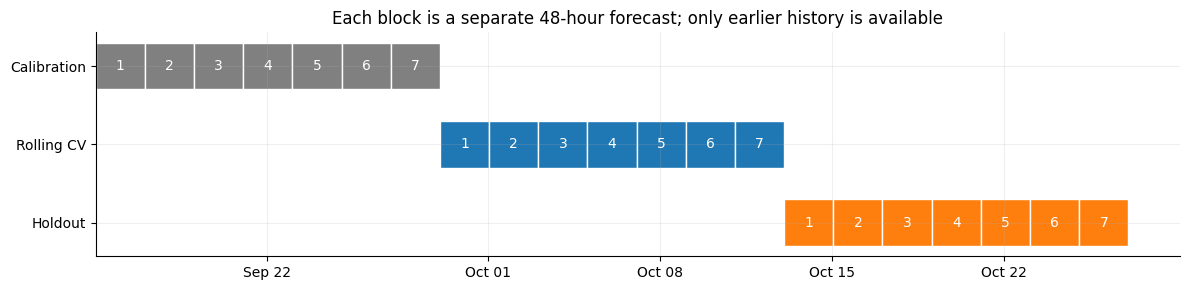

In [15]:
holdout_start = N - HOLDOUT_DAYS * DAY
holdout_origins = np.arange(holdout_start, N - H + 1, H, dtype=int)
cv_origins = np.arange(holdout_start - CV_FOLDS * H, holdout_start, H, dtype=int)
calibration_origins = np.arange(cv_origins[0] - CALIBRATION_FOLDS * H, cv_origins[0], H, dtype=int)
development_origins = np.concatenate([calibration_origins, cv_origins])
assert calibration_origins[0] >= (max(CONTEXT_DAYS, TRAIN_DAYS) + 7) * DAY
assert calibration_origins[-1] + H <= cv_origins[0]
assert cv_origins[-1] + H <= holdout_origins[0]

display(pd.DataFrame([
    {'stage': stage, 'windows': len(origins), 'first target': data.ds.iloc[origins[0]],
     'last target': data.ds.iloc[origins[-1] + H - 1]}
    for stage, origins in [('Calibration', calibration_origins), ('CV / selection', cv_origins),
                           ('Retrospective holdout', holdout_origins)]
]))


fig, ax = plt.subplots(figsize=(12, 3))
for row, (stage, origins, color) in enumerate([
    ('Calibration', calibration_origins, 'grey'),
    ('Rolling CV', cv_origins, 'tab:blue'),
    ('Holdout', holdout_origins, 'tab:orange'),
]):
    for fold, origin in enumerate(origins, 1):
        start = mdates.date2num(data.ds.iloc[origin])
        ax.barh(row, H / DAY, left=start, height=0.6, color=color, edgecolor='white')
        ax.text(start + H / DAY / 2, row, str(fold), ha='center', va='center', color='white')
ax.set_yticks([0, 1, 2], ['Calibration', 'Rolling CV', 'Holdout'])
ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_title('Each block is a separate 48-hour forecast; only earlier history is available')
plt.tight_layout()
plt.show()

## 3. Forecast functions

Timestral uses a fixed 180-day context, with small batches and cached predictions. We compare its median forecasts. All candidates receive intervals calibrated against raw errors using the same method.

LightGBM uses the existing 19 lag, calendar and weather features, learns `log(y)`, and is refitted on the previous 180 days at each origin. Seasonal naïve repeats the last observed 24 hours twice.

In [16]:
LGBM_PARAMS = dict(objective='regression', n_estimators=180, learning_rate=0.05,
                   num_leaves=15, min_child_samples=40, reg_lambda=2.0,
                   random_state=SEED, n_jobs=4, verbosity=-1)

frames = []
for origin in range(int(calibration_origins[0]) - TRAIN_DAYS * DAY, N - H + 1, DAY):
    frame = make_features(y, origin, data.iloc[origin:origin + H])
    frame['origin'] = origin
    frame['target'] = y[origin:origin + H]
    frames.append(frame)
supervised = pd.concat(frames, ignore_index=True)
feature_names = [c for c in supervised if c not in ('origin', 'target')]
lgbm_cache = {}


def lgbm_forecast(origin):
    if origin not in lgbm_cache:
        train = supervised[supervised.origin.between(origin - TRAIN_DAYS * DAY, origin - H)]
        booster = lgb.LGBMRegressor(**LGBM_PARAMS).fit(train[feature_names], np.log(train.target))
        weather = future_weather if origin == N else data.iloc[origin:origin + H]
        lgbm_cache[origin] = np.exp(booster.predict(make_features(y, origin, weather)[feature_names]))
    return lgbm_cache[origin]

In [17]:
model = load_timestral(MODEL_ID)
timestral_cache = {}


def timestral_points(origins, covariates=WEATHER_COLUMNS):
    config = tuple(covariates)
    missing = [int(o) for o in origins if (config, int(o)) not in timestral_cache]
    for start in range(0, len(missing), BATCH_SIZE):
        batch = missing[start:start + BATCH_SIZE]
        forecast_weather = {N: future_weather} if N in batch else None
        forecasts = timestral_forecast(model, data, batch, CONTEXT_DAYS,
                                       covariates, forecast_weather)
        for origin, (point, _, _) in forecasts.items():
            timestral_cache[(config, origin)] = point
    return {int(o): timestral_cache[(config, int(o))] for o in origins}

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

## 4. Compare the main models immediately

Intervals use the 95th percentile of absolute **raw** errors, separately for forecast day and day/night. Errors are divided by the previous seven-day generation level during calibration; widths are multiplied by the current past level at prediction time. This accommodates changing generation levels, but 95% coverage is a target, not a guarantee.

For selection, interval widths use **calibration windows only**. Their Winkler scores are then measured on the separate CV windows.

**Selection score (day 2)** = `0.3 × RMSE / naïve RMSE + 0.3 × MAPE / naïve MAPE + 0.4 × Winkler / naïve Winkler`. Lower is better; naïve scores 1. This follows the assignment's weights, but uses metric ratios instead of unknown class ranks. MAPE is retained because it is graded, although near-zero observations can dominate it.

In [18]:
def fit_widths(points, origins):
    return calibrate_halfwidths(y, daylight, origins, points, level_days=LEVEL_DAYS)


def forecast_band(origin, point, widths):
    flags = future_weather.daylight.to_numpy(int) if origin == N else daylight[origin:origin + H]
    return interval(point, flags, widths, recent_level(y, origin, LEVEL_DAYS))


def metrics(points, origins, widths, part='25–48'):
    sl = PARTS[part]
    actual = np.concatenate([y[o:o + H][sl] for o in origins])
    predicted = np.concatenate([points[o][sl] for o in origins])
    bands = [forecast_band(o, points[o], widths) for o in origins]
    lower = np.concatenate([lo[sl] for lo, hi in bands])
    upper = np.concatenate([hi[sl] for lo, hi in bands])
    return {'RMSE': rmse(actual, predicted), 'MAPE %': mape(actual, predicted),
            'Winkler': winkler(actual, lower, upper),
            'Coverage %': 100 * np.mean((actual >= lower) & (actual <= upper)),
            'Mean width': np.mean(upper - lower)}


def selection_table(candidates):
    table = pd.DataFrame({name: metrics(points, cv_origins, fit_widths(points, calibration_origins))
                          for name, points in candidates.items()}).T
    relative = table[['RMSE', 'MAPE %', 'Winkler']].div(naive_reference)
    table['Score'] = relative.mul([0.3, 0.3, 0.4]).sum(axis=1)
    return table.sort_values('Score')

Forecasting calibration + CV windows: Timestral and LightGBM...
CV: hours 25–48, intervals calibrated on earlier windows


,RMSE,MAPE %,Winkler,Coverage %,Mean width,Score
Timestral: raw history,220.45,35.19,1592.64,77.98,444.17,0.86
Previous LGBM candidate,274.70,33.35,1474.44,88.10,732.58,0.87
LightGBM log(y),287.88,34.30,1598.73,88.69,747.67,0.92
Seasonal naive,308.86,46.03,1520.88,90.48,884.67,1.00


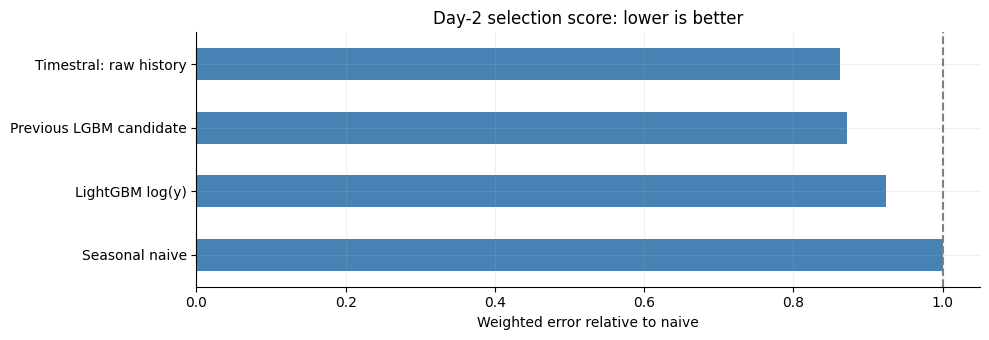

In [19]:
RAW = 'Timestral: raw history'
LGBM = 'LightGBM log(y)'
NAIVE = 'Seasonal naive'
PREVIOUS = 'Previous LGBM candidate'

cv_points = {NAIVE: {int(o): seasonal_naive(y, o) for o in development_origins}}
naive_reference = pd.Series(metrics(cv_points[NAIVE], cv_origins,
                                    fit_widths(cv_points[NAIVE], calibration_origins)))[['RMSE', 'MAPE %', 'Winkler']]

print('Forecasting calibration + CV windows: Timestral and LightGBM...')
cv_points[RAW] = timestral_points(development_origins)
cv_points[LGBM] = {int(o): lgbm_forecast(o) for o in development_origins}
cv_points[PREVIOUS] = {
    int(o): np.concatenate([cv_points[LGBM][o][:DAY],
                            0.75 * cv_points[LGBM][o][DAY:] + 0.25 * cv_points[NAIVE][o][DAY:]])
    for o in development_origins
}
baseline_table = selection_table(cv_points)
print('CV: hours 25–48, intervals calibrated on earlier windows')
display(baseline_table.round(2))

fig, ax = plt.subplots(figsize=(10, 3.5))
baseline_table['Score'].sort_values().plot.barh(ax=ax, color='steelblue')
ax.invert_yaxis()
ax.axvline(1, color='grey', ls='--')
ax.set(title='Day-2 selection score: lower is better', xlabel='Weighted error relative to naive', ylabel='')
plt.tight_layout()
plt.show()

### 4.1 Rolling cross-validation: every window

CV consists of **seven separate forecasts**, not one train/test split. At each origin, Timestral reads the preceding 180 days and LightGBM is refitted on its preceding training window. Each model predicts the same next 48 hours.

The table shows day-2 errors for each window. The curves compare day 1 and day 2 separately. The grid then shows raw actual values against all three main forecasts for **every** CV window. These cells use the predictions already in memory; they do not call the models again.

Rolling CV: each row is a different forecast origin; hours 25–48


RMSE                                        \
Model               LightGBM log(y) Seasonal naive Timestral: raw history   
Origin                                                                      
2026-09-29 01:00:00          225.62         285.81                 181.57   
2026-10-01 01:00:00          222.53         225.76                 192.71   
2026-10-03 01:00:00          225.58         353.97                 223.07   
2026-10-05 01:00:00          317.13         384.52                 304.19   
2026-10-07 01:00:00          409.89         383.24                 174.23   
2026-10-09 01:00:00          362.25         281.64                 280.84   
2026-10-11 01:00:00          170.36         189.05                 136.30   

                             MAPE %                                        \
Model               LightGBM log(y) Seasonal naive Timestral: raw history   
Origin                                                                      
2026-09-29 01:00:00           23.89          41.60                  31.04   
2026-10-01 01:00:00           60.23          55.57                  69.89   
2026-10-03 01:00:00           27.39          37.83                  37.85   
2026-10-05 01:00:00           35.08          82.19                  47.78   
2026-10-07 01:00:00           43.01          27.49                  23.30   
2026-10-09 01:00:00           24.95          52.81                  15.78   
2026-10-11 01:00:00           25.54          24.71                  20.68   

                            Winkler                                        \
Model               LightGBM log(y) Seasonal naive Timestral: raw history   
Origin                                                                      
2026-09-29 01:00:00          927.83        1023.60                 704.10   
2026-10-01 01:00:00          738.06         878.96                1016.71   
2026-10-03 01:00:00         1213.56        2113.55                1851.65   
2026-10-05 01:00:00         1850.76        2456.73                3287.47   
2026-10-07 01:00:00         3058.08        2080.49                 970.80   
2026-10-09 01:00:00         2718.30        1226.34                2908.60   
2026-10-11 01:00:00          684.49         866.49                 409.16   

                         Coverage %                                        
Model               LightGBM log(y) Seasonal naive Timestral: raw history  
Origin                                                                     
2026-09-29 01:00:00           95.83          95.83                  87.50  
2026-10-01 01:00:00          100.00         100.00                  66.67  
2026-10-03 01:00:00           91.67          83.33                  75.00  
2026-10-05 01:00:00           83.33          75.00                  58.33  
2026-10-07 01:00:00           66.67          87.50                  75.00  
2026-10-09 01:00:00           83.33          91.67                  83.33  
2026-10-11 01:00:00          100.00         100.00                 100.00

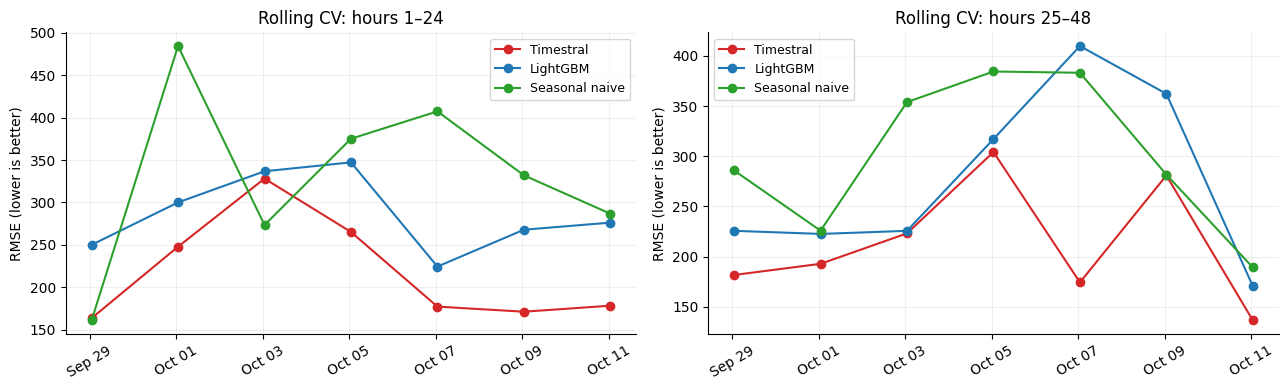

In [20]:
plot_names = {RAW: 'Timestral', LGBM: 'LightGBM', NAIVE: 'Seasonal naive',
              PREVIOUS: 'Previous LGBM candidate'}
plot_colors = {RAW: 'tab:red', LGBM: 'tab:blue', NAIVE: 'tab:green', PREVIOUS: 'tab:cyan'}
cv_plot_models = [RAW, LGBM, NAIVE]


def window_scores(points, origins, widths):
    return pd.DataFrame([
        {'Origin': data.ds.iloc[o], 'Model': name, 'Hours': part,
         **metrics(points[name], [o], widths[name], part)}
        for name in points for o in origins for part in PARTS
    ])


cv_plot_widths = {name: fit_widths(cv_points[name], calibration_origins) for name in cv_plot_models}
cv_window_scores = window_scores({name: cv_points[name] for name in cv_plot_models},
                                 cv_origins, cv_plot_widths)
print('Rolling CV: each row is a different forecast origin; hours 25–48')
display(cv_window_scores.query('Hours == "25–48"').pivot(
    index='Origin', columns='Model', values=['RMSE', 'MAPE %', 'Winkler', 'Coverage %']
).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, part in zip(axes, ['1–24', '25–48']):
    for name in cv_plot_models:
        rows = cv_window_scores[(cv_window_scores.Model == name) & (cv_window_scores.Hours == part)]
        ax.plot(rows.Origin, rows.RMSE, marker='o', color=plot_colors[name], label=plot_names[name])
    ax.set(title=f'Rolling CV: hours {part}', ylabel='RMSE (lower is better)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

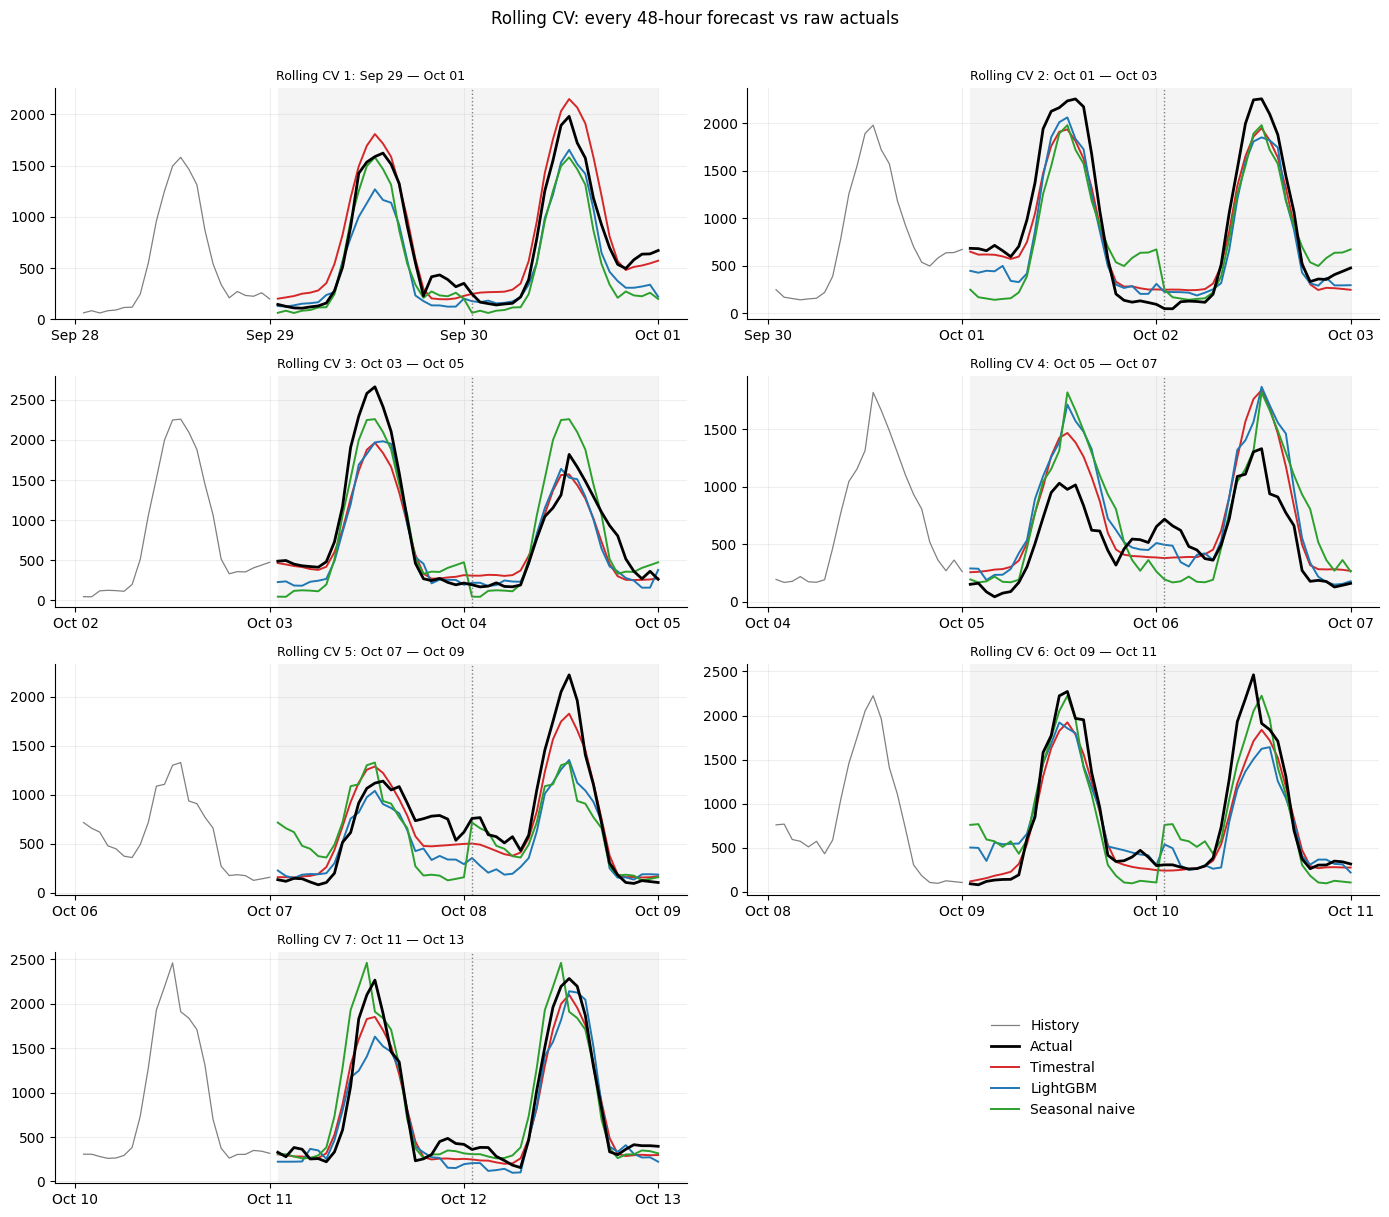

In [21]:
from final.lgbm_baseline import plot_window_grid


def show_windows(points, origins, names, stage, bands=None):
    rows = (len(origins) + 2) // 2  # One spare panel for the shared legend.
    fig, axes = plt.subplots(rows, 2, figsize=(14, 3 * rows), squeeze=False)
    plot_window_grid(
        fig, axes, data.ds, y, origins,
        {o: {name: points[name][o] for name in names} for o in origins},
        [f'{stage} {i}: {data.ds.iloc[o]:%b %d} — {data.ds.iloc[o + H - 1]:%b %d}'
         for i, o in enumerate(origins, 1)],
        bands=bands, names=plot_names, colors=plot_colors,
    )
    fig.suptitle(f'{stage}: every 48-hour forecast vs raw actuals', y=1.01)
    plt.tight_layout()
    plt.show()


show_windows(cv_points, cv_origins, cv_plot_models, 'Rolling CV')

## 5. Remove weather only if CV improves

Try removing one weather group at a time and removing all weather. The best actual configuration is retained, including the full model if removal does not help.

This is a small group ablation, not an exhaustive search over all feature combinations. LightGBM keeps its existing feature set. The selected Timestral weather columns are reused for blends, holdout and the final forecast.

In [22]:
history_name = RAW
timestral_configs = {RAW: WEATHER_COLUMNS}
groups_to_remove = {
    'without sun/clouds': ['cloud_cover', 'daylight'],
    'without wind/density': ['wind_speed', 'air_density'],
    'without temperature/pressure/humidity': ['temperature', 'pressure', 'humidity'],
    'without weather': WEATHER_COLUMNS,
}
ablation_names = [history_name]
for label, removed in groups_to_remove.items():
    name = f'{history_name} — {label}'
    kept = [c for c in WEATHER_COLUMNS if c not in removed]
    print(label)
    timestral_configs[name] = kept
    cv_points[name] = timestral_points(development_origins, kept)
    ablation_names.append(name)

ablation_table = selection_table({name: cv_points[name] for name in ablation_names})
ablation_table['Change vs full'] = ablation_table.Score - baseline_table.loc[history_name, 'Score']
display(ablation_table.round(3))
best_timestral = ablation_table.index[0]
chosen_covariates = timestral_configs[best_timestral]
print('Chosen history: raw')
print('Weather kept:', ', '.join(chosen_covariates) or 'none')
print('Weather removed:', ', '.join(c for c in WEATHER_COLUMNS if c not in chosen_covariates) or 'none')

without sun/clouds
without wind/density
without temperature/pressure/humidity
without weather


,RMSE,MAPE %,Winkler,Coverage %,Mean width,Score,Change vs full
Timestral: raw history,220.45,35.19,1592.64,77.98,444.17,0.86,0.00
Timestral: raw history — without sun/clouds,206.74,34.49,1725.85,74.41,394.17,0.88,0.02
Timestral: raw history — without wind/density,238.24,46.55,1423.09,86.31,704.05,0.91,0.05
Timestral: raw history — without temperature/pressure/humidity,225.65,38.43,1871.29,66.67,412.69,0.96,0.10
Timestral: raw history — without weather,281.48,54.95,1650.03,79.76,765.46,1.07,0.20


Chosen history: raw
Weather kept: cloud_cover, temperature, wind_speed, pressure, humidity, daylight, air_density
Weather removed: none


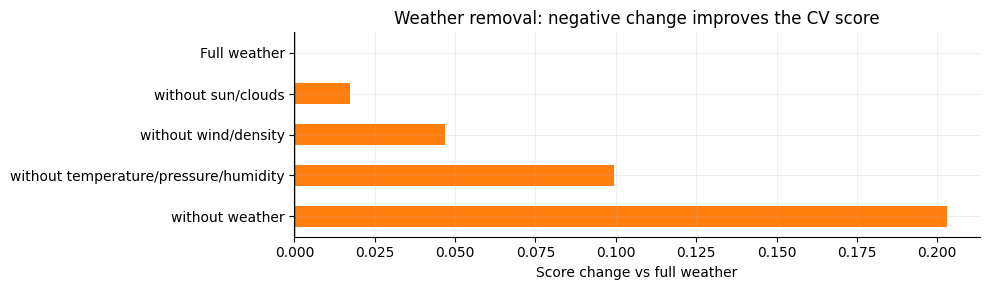

In [23]:
changes = ablation_table['Change vs full'].copy()
changes.index = ['Full weather' if name == RAW else name.split(' — ')[-1] for name in changes.index]
fig, ax = plt.subplots(figsize=(10, 3))
changes.sort_values().plot.barh(ax=ax, color=['tab:green' if value < 0 else 'tab:orange'
                                           for value in changes.sort_values()])
ax.axvline(0, color='black', lw=1)
ax.invert_yaxis()
ax.set(title='Weather removal: negative change improves the CV score', xlabel='Score change vs full weather', ylabel='')
plt.tight_layout()
plt.show()

## 6. Choose weights for Timestral + seasonal naïve + LightGBM

The submission uses **all three models**, as requested. Search weights in steps of **10 percentage points**, with **at least 10% for each model** and a total of 100%: 36 combinations. This positive minimum keeps all three models in the blend; it is a chosen constraint, not evidence that every model improves accuracy. Use the same weights for all 48 hours, chosen by the assignment's day-2 objective.

For every combination:

1. Combine the point forecasts already computed on calibration and CV windows.
2. Calibrate that combination's intervals using **only the earlier calibration windows**.
3. Score it on the separate CV windows: `0.3 × relative RMSE + 0.3 × relative MAPE + 0.4 × relative Winkler`, for hours 25–48.

Freeze the best three-model weights before looking at holdout. Keep the previous simple blends, including 60/20/20, and the individual models as references. The table also reports the best candidate overall; the submission uses the best three-model blend even if another candidate scores lower.

Selecting among 36 combinations on seven CV windows can overfit. The holdout remains retrospective and does not change the weights. LightGBM contributes its point predictions; each blend's interval is calibrated from its own errors.

If sections 1–5, including the plotting helpers in section 4.1, have already run in this kernel, rerun sections 6–8. No new model calls are needed for the weight search.

In [24]:
THREE_WAY = 'Timestral + naive + LGBM (CV weights)'
FIXED_THREE_WAY = '60% Timestral + 20% naive + 20% LGBM'

# Start from component predictions, so rerunning this cell drops old blend results.
base_names = [NAIVE, LGBM, *timestral_configs]
cv_points = {name: cv_points[name] for name in base_names}
recipes = {name: {name: np.ones(H)} for name in base_names}
recipes[PREVIOUS] = {LGBM: np.r_[np.ones(DAY), np.full(DAY, 0.75)],
                     NAIVE: np.r_[np.zeros(DAY), np.full(DAY, 0.25)]}
recipes['75% Timestral + 25% naive'] = {best_timestral: np.full(H, 0.75), NAIVE: np.full(H, 0.25)}
recipes['50% Timestral + 50% naive'] = {best_timestral: np.full(H, 0.5), NAIVE: np.full(H, 0.5)}
recipes['75% Timestral + 25% LGBM'] = {best_timestral: np.full(H, 0.75), LGBM: np.full(H, 0.25)}
recipes[FIXED_THREE_WAY] = {best_timestral: np.full(H, 0.60), NAIVE: np.full(H, 0.20), LGBM: np.full(H, 0.20)}


def blend_points(recipe, components, origins):
    return {int(o): sum(weight * components[name][o] for name, weight in recipe.items()) for o in origins}


for name, recipe in recipes.items():
    cv_points[name] = blend_points(recipe, cv_points, development_origins)

grid_weights = {}
for t in range(1, 9):
    for n in range(1, 10 - t):
        l = 10 - t - n
        grid_weights[f'{10*t}/{10*n}/{10*l}'] = {best_timestral: t / 10, NAIVE: n / 10, LGBM: l / 10}

grid_points = {
    label: blend_points({name: np.full(H, weight) for name, weight in weights.items()},
                        cv_points, development_origins)
    for label, weights in grid_weights.items()
}
# selection_table calibrates on calibration_origins, then scores cv_origins only.
weight_scores = selection_table(grid_points)
best_grid = weight_scores.index[0]
chosen_weights = grid_weights[best_grid]
assert all(weight >= 0.10 for weight in chosen_weights.values())
assert np.isclose(sum(chosen_weights.values()), 1)

weight_table = pd.DataFrame.from_dict(grid_weights, orient='index').rename(
    columns={best_timestral: 'Timestral %', NAIVE: 'Naive %', LGBM: 'LightGBM %'}
) * 100
print('Best 5 weight combinations on CV, hours 25–48 (row label: T / N / L)')
display(weight_table.join(weight_scores).loc[weight_scores.index].head(5).round(3))

recipes[THREE_WAY] = {name: np.full(H, weight) for name, weight in chosen_weights.items()}
cv_points[THREE_WAY] = grid_points[best_grid]
selection = selection_table(cv_points)
cv_best_name = selection.index[0]
selected_name = THREE_WAY  # Requested submission: best blend with all three models.
selected_recipe = recipes[selected_name]

print('CV comparison, hours 25–48')
display(selection.round(3))
print(f'Best candidate overall: {cv_best_name}; score = {selection.loc[cv_best_name, "Score"]:.3f}')
print(f'Chosen three-model blend: {best_grid}; score = {selection.loc[selected_name, "Score"]:.3f}')
print('Frozen weights below are used on both forecast days:')
display(weight_table.loc[[best_grid]].round(0))

Best 5 weight combinations on CV, hours 25–48 (row label: T / N / L)


,Timestral %,Naive %,LightGBM %,RMSE,MAPE %,Winkler,Coverage %,Mean width,Score
60/30/10,60.0,30.0,10.0,217.32,32.09,1476.91,85.12,537.37,0.81
50/40/10,50.0,40.0,10.0,223.64,32.28,1462.49,86.31,582.66,0.81
70/20/10,70.0,20.0,10.0,214.75,32.43,1525.27,81.55,494.42,0.82
40/50/10,40.0,50.0,10.0,233.40,33.11,1453.66,86.91,628.97,0.82
40/40/20,40.0,40.0,20.0,231.32,32.20,1504.24,85.12,591.03,0.83


CV comparison, hours 25–48


,RMSE,MAPE %,Winkler,Coverage %,Mean width,Score
75% Timestral + 25% naive,211.16,32.71,1421.25,84.52,519.51,0.79
50% Timestral + 50% naive,225.95,33.09,1379.39,88.09,632.53,0.80
Timestral + naive + LGBM (CV weights),217.32,32.09,1476.91,85.12,537.37,0.81
60% Timestral + 20% naive + 20% LGBM,219.93,32.02,1618.81,80.36,496.81,0.85
Timestral: raw history,220.45,35.19,1592.64,77.98,444.17,0.86
Previous LGBM candidate,274.70,33.35,1474.44,88.09,732.58,0.87
Timestral: raw history — without sun/clouds,206.74,34.49,1725.85,74.41,394.17,0.88
75% Timestral + 25% LGBM,225.17,33.25,1730.11,78.57,454.24,0.89
Timestral: raw history — without wind/density,238.24,46.55,1423.09,86.31,704.05,0.91
LightGBM log(y),287.88,34.30,1598.73,88.69,747.67,0.92


Best candidate overall: 75% Timestral + 25% naive; score = 0.792
Chosen three-model blend: 60/30/10; score = 0.809
Frozen weights below are used on both forecast days:


,Timestral %,Naive %,LightGBM %
60/30/10,60.0,30.0,10.0


### 6.1 Does the chosen three-model blend perform consistently?

Compare the blend with CV-chosen weights against the main baselines on each CV window. The three panels show **day-2** RMSE, MAPE and Winkler. A lower pooled score does not imply winning every window or every metric. Interval widths here still use calibration windows only.

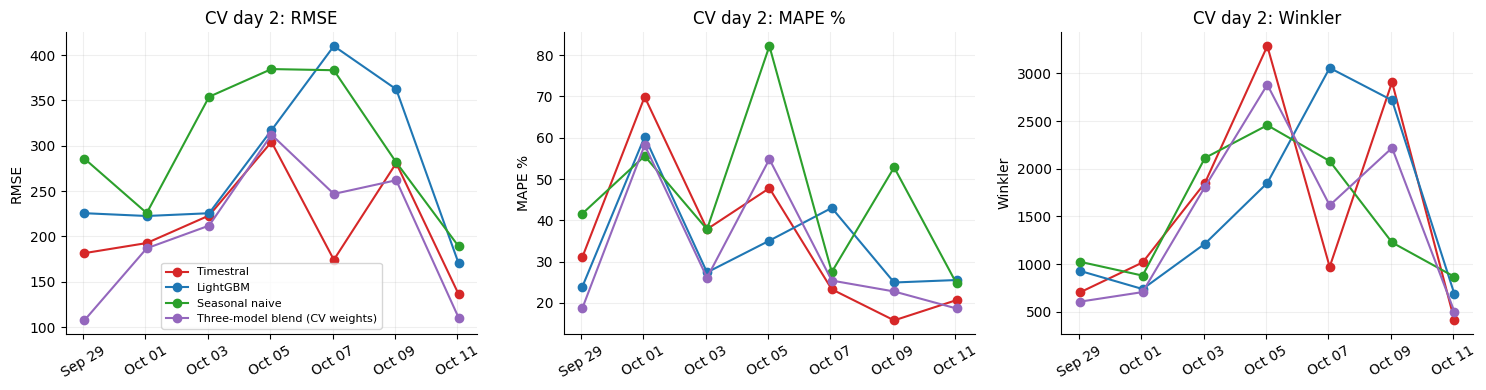

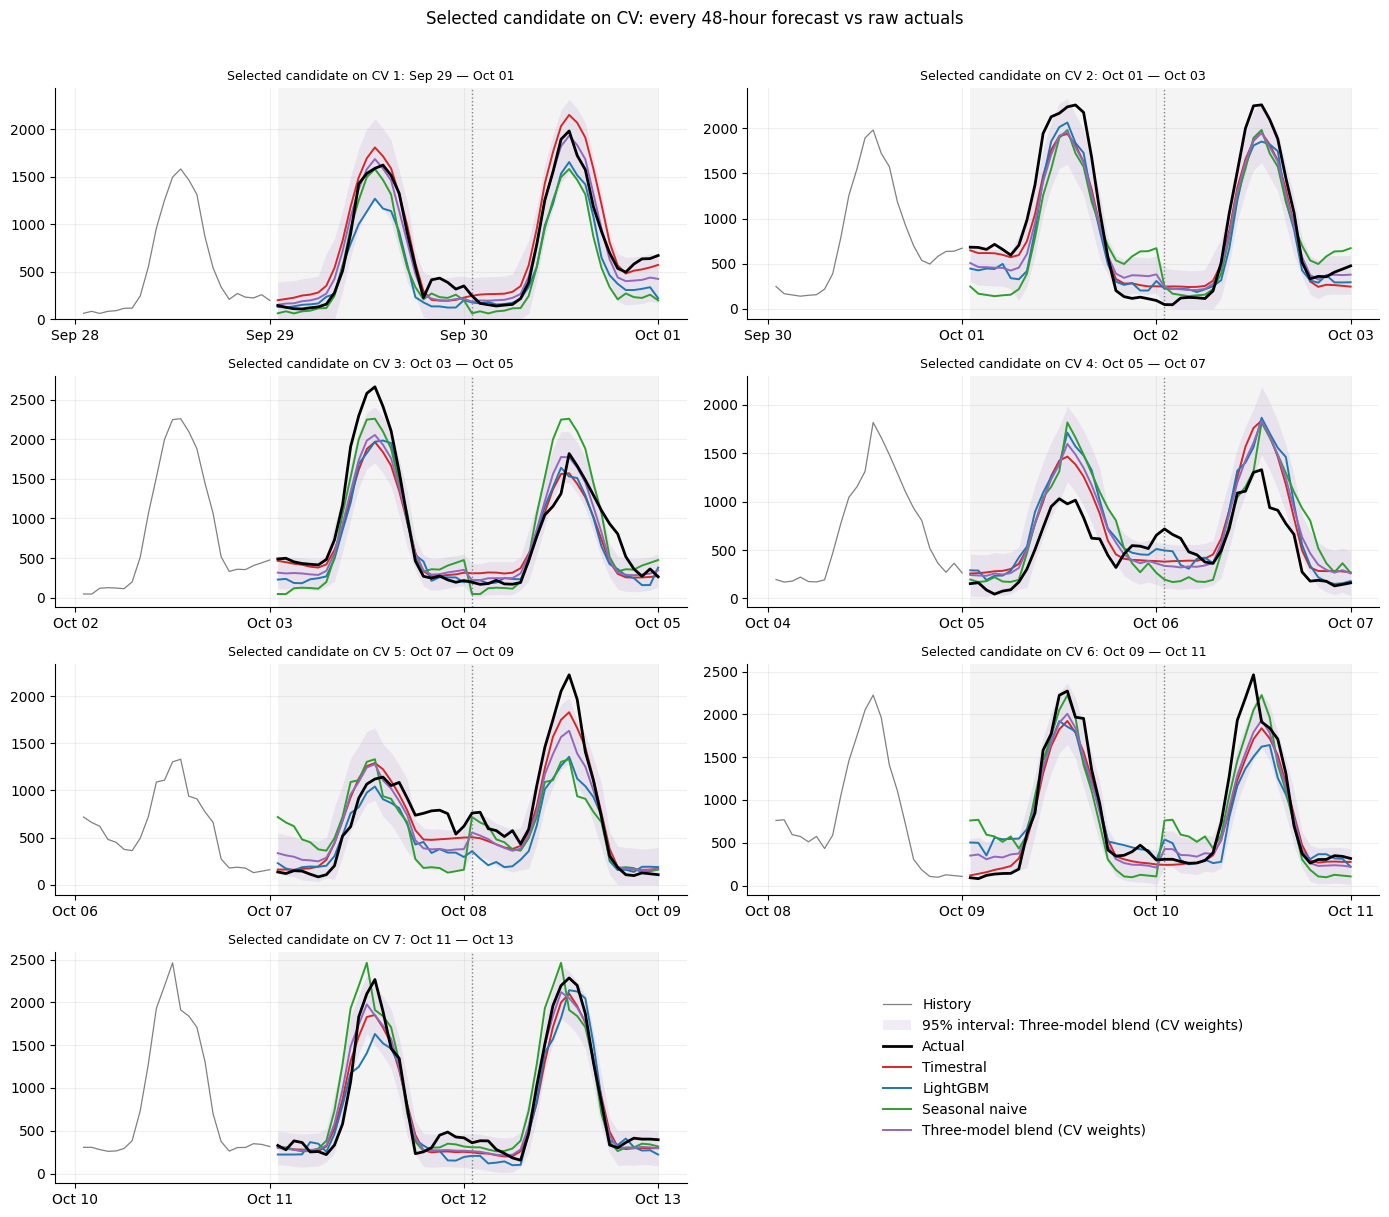

In [25]:
plot_names[THREE_WAY] = 'Three-model blend (CV weights)'
plot_colors[THREE_WAY] = 'tab:purple'
if selected_name not in plot_names:
    plot_names[selected_name] = 'Selected candidate'
    plot_colors[selected_name] = 'tab:purple'
selected_plot_models = list(dict.fromkeys([RAW, LGBM, NAIVE, THREE_WAY, selected_name]))
selected_cv_widths = {name: fit_widths(cv_points[name], calibration_origins) for name in selected_plot_models}
selected_cv_scores = window_scores({name: cv_points[name] for name in selected_plot_models},
                                   cv_origins, selected_cv_widths)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ['RMSE', 'MAPE %', 'Winkler']):
    for name in selected_plot_models:
        rows = selected_cv_scores[(selected_cv_scores.Model == name) & (selected_cv_scores.Hours == '25–48')]
        ax.plot(rows.Origin, rows[metric], marker='o', color=plot_colors[name], label=plot_names[name])
    ax.set(title=f'CV day 2: {metric}', ylabel=metric)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.tick_params(axis='x', rotation=30)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

selected_cv_bands = {o: (selected_name, *forecast_band(o, cv_points[selected_name][o],
                                                     selected_cv_widths[selected_name])) for o in cv_origins}
show_windows(cv_points, cv_origins, selected_plot_models, 'Selected candidate on CV', selected_cv_bands)

## 7. Retrospective holdout: inspect the frozen choice

After selection, refit interval widths on all 14 development windows. Keep these widths and the chosen recipe fixed for the holdout and final export. Every point forecast still uses only history available at its own origin. LightGBM is refitted at each origin.

The table reports raw actuals on both days and all 48 hours. The plots show every holdout window, the latest window in detail, and mean error by forecast hour. Positive error means underprediction. This is a diagnostic; the export continues to use the three-model blend with its weights chosen on CV.

In [26]:
def component_points(names, origins):
    results = {}
    for name in names:
        if name == NAIVE:
            results[name] = {int(o): seasonal_naive(y, o) for o in origins}
        elif name == LGBM:
            results[name] = {int(o): lgbm_forecast(o) for o in origins}
        else:
            columns = timestral_configs[name]
            results[name] = timestral_points(origins, columns)
    return results


comparison_names = list(dict.fromkeys([RAW, LGBM, NAIVE, PREVIOUS, '75% Timestral + 25% naive', FIXED_THREE_WAY, THREE_WAY]))
needed_components = list(dict.fromkeys(c for name in comparison_names for c in recipes[name]))
holdout_components = component_points(needed_components, holdout_origins)
holdout_points = {name: blend_points(recipes[name], holdout_components, holdout_origins)
                  for name in comparison_names}
frozen_widths = {name: fit_widths(cv_points[name], development_origins) for name in comparison_names}

holdout_table = pd.DataFrame([
    {'Model': name, 'Hours': part, **metrics(holdout_points[name], holdout_origins, frozen_widths[name], part)}
    for name in comparison_names for part in PARTS
]).set_index(['Model', 'Hours'])
print('Holdout: hours 25–48 (the graded horizon)')
display(holdout_table.xs('25–48', level='Hours').round(2))
print('Frozen choice: day 1, day 2, full horizon')
display(holdout_table.loc[selected_name].round(2))

Holdout: hours 25–48 (the graded horizon)


,RMSE,MAPE %,Winkler,Coverage %,Mean width
Model,,,,,
Timestral: raw history,245.27,134.79,1875.41,83.93,539.59
LightGBM log(y),260.11,220.13,934.93,94.05,804.98
Seasonal naive,344.42,437.78,1718.50,91.67,901.84
Previous LGBM candidate,259.70,269.08,1072.36,91.07,770.75
75% Timestral + 25% naive,244.47,206.33,1539.03,83.33,590.55
60% Timestral + 20% naive + 20% LGBM,232.60,205.34,1309.72,88.69,608.82
Timestral + naive + LGBM (CV weights),241.92,227.94,1469.84,86.31,598.06


Frozen choice: day 1, day 2, full horizon


,RMSE,MAPE %,Winkler,Coverage %,Mean width
Hours,,,,,
1–24,150.37,328.50,644.74,99.40,638.51
25–48,241.92,227.94,1469.84,86.31,598.06
1–48,201.42,278.22,1057.29,92.86,618.29


### 7.1 Every holdout window and interval coverage

Black is the raw actual series. Compare the chosen three-model blend, Timestral, LightGBM and naïve on all seven windows; the shaded interval belongs to the selected candidate. The dotted vertical line separates days 1 and 2. The table and coverage plot expose misses that a full-horizon average can hide.

Selected candidate: day-2 metrics for every holdout window


,RMSE,MAPE %,Winkler,Coverage %
Origin,,,,
2026-10-13 01:00:00,214.62,194.76,682.56,100.00
2026-10-15 01:00:00,417.44,44.45,4860.75,58.33
2026-10-17 01:00:00,210.40,929.97,1566.31,70.83
2026-10-19 01:00:00,142.55,139.03,639.23,100.00
2026-10-21 01:00:00,262.79,75.44,1149.67,87.50
2026-10-23 01:00:00,155.15,140.60,505.30,100.00
2026-10-25 01:00:00,177.92,71.36,885.06,87.50


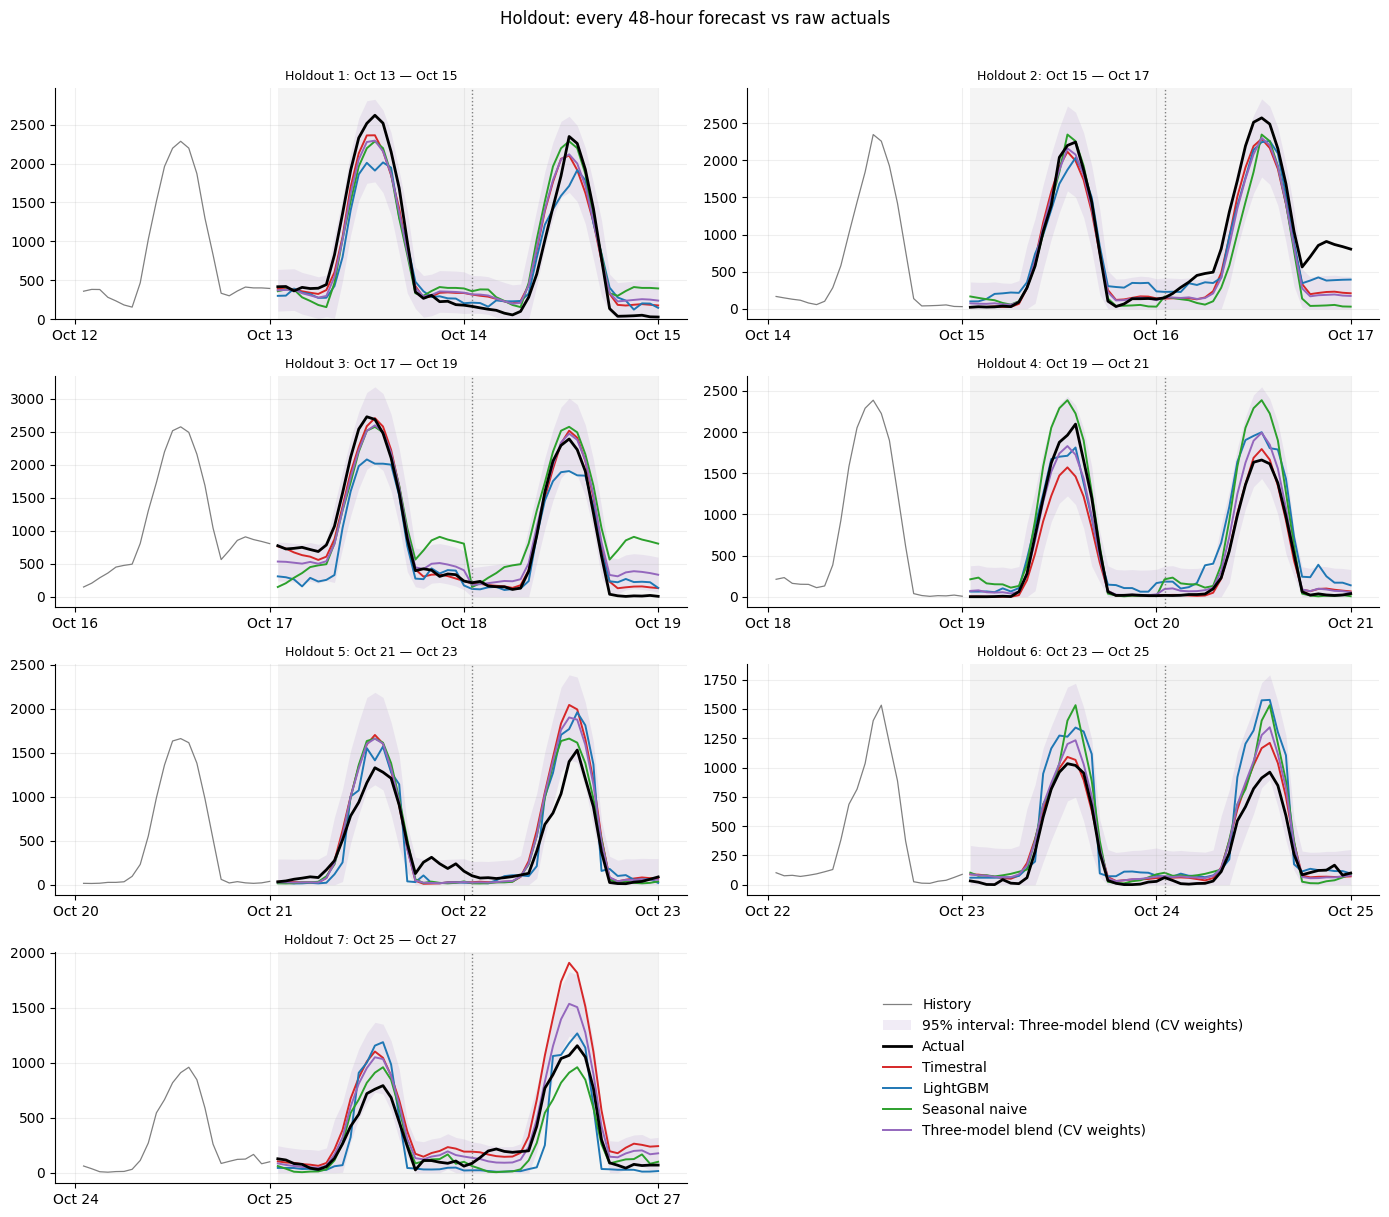

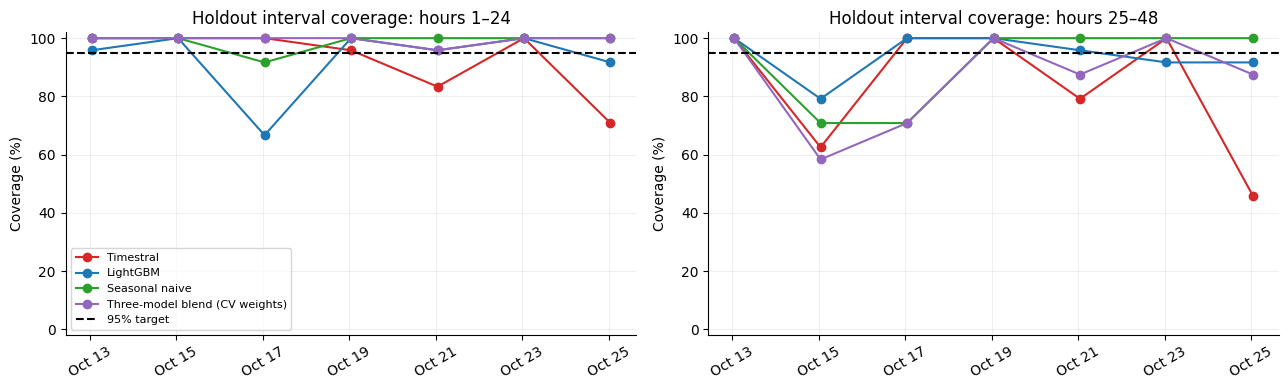

In [27]:
holdout_window_scores = window_scores({name: holdout_points[name] for name in selected_plot_models},
                                      holdout_origins, frozen_widths)
print('Selected candidate: day-2 metrics for every holdout window')
display(holdout_window_scores[(holdout_window_scores.Model == selected_name)
                             & (holdout_window_scores.Hours == '25–48')]
        .set_index('Origin')[['RMSE', 'MAPE %', 'Winkler', 'Coverage %']].round(2))

selected_holdout_bands = {o: (selected_name, *forecast_band(o, holdout_points[selected_name][o],
                                                          frozen_widths[selected_name])) for o in holdout_origins}
show_windows(holdout_points, holdout_origins, selected_plot_models, 'Holdout', selected_holdout_bands)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, part in zip(axes, ['1–24', '25–48']):
    for name in selected_plot_models:
        rows = holdout_window_scores[(holdout_window_scores.Model == name) & (holdout_window_scores.Hours == part)]
        ax.plot(rows.Origin, rows['Coverage %'], marker='o', color=plot_colors[name], label=plot_names[name])
    ax.axhline(95, color='black', ls='--', label='95% target')
    ax.set(title=f'Holdout interval coverage: hours {part}', ylabel='Coverage (%)', ylim=(-2, 102))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.tick_params(axis='x', rotation=30)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

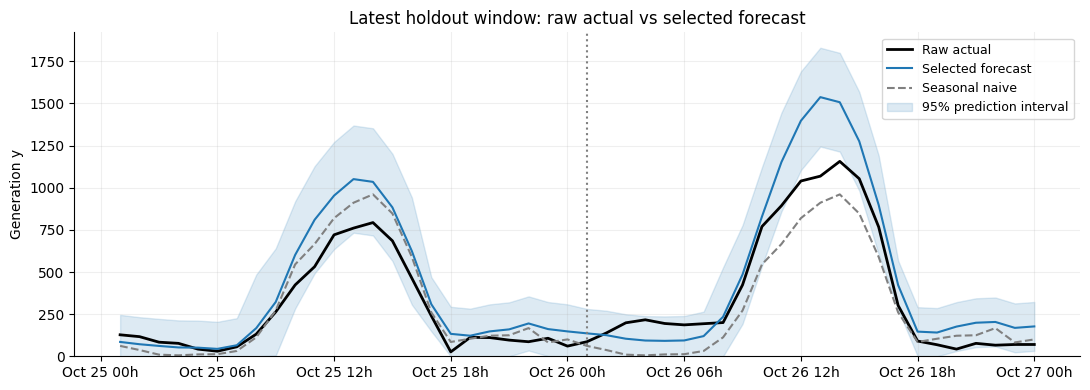

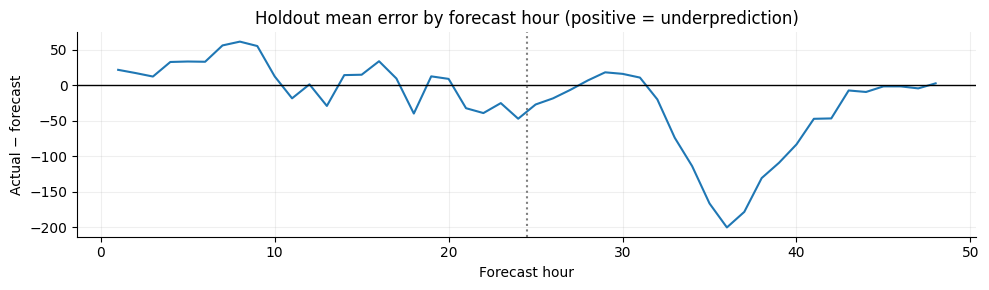

In [28]:
origin = int(holdout_origins[-1])
dates = data.ds.iloc[origin:origin + H]
point = holdout_points[selected_name][origin]
lower, upper = forecast_band(origin, point, frozen_widths[selected_name])
fig, ax = plt.subplots()
ax.plot(dates, y[origin:origin + H], color='black', lw=2, label='Raw actual')
ax.plot(dates, point, color='tab:blue', label='Selected forecast')
ax.plot(dates, holdout_points[NAIVE][origin], color='grey', ls='--', label='Seasonal naive')
ax.fill_between(dates, lower, upper, color='tab:blue', alpha=0.15, label='95% prediction interval')
ax.axvline(dates.iloc[DAY], color='grey', ls=':')
ax.set(title='Latest holdout window: raw actual vs selected forecast', ylabel='Generation y', ylim=(0, None))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %Hh'))
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

errors = np.stack([y[o:o + H] - holdout_points[selected_name][o] for o in holdout_origins])
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(1, H + 1), errors.mean(axis=0), color='tab:blue')
ax.axhline(0, color='black', lw=1)
ax.axvline(DAY + 0.5, color='grey', ls=':')
ax.set(title='Holdout mean error by forecast hour (positive = underprediction)',
       xlabel='Forecast hour', ylabel='Actual − forecast')
plt.tight_layout()
plt.show()

## 8. The actual 48-hour prediction and submission

Forecast with the chosen Timestral + seasonal naïve + LightGBM blend, using all available historical observations. Keep the selected weather columns, weights chosen on CV, and interval calibration frozen. Future weather comes from `weather_forecast.csv`.

The table below is the actual submission: `ds`, `forecast`, `lower_95`, `upper_95`. The final cell checks all 48 timestamps, finite values and ordered bounds, then writes **`output/BARANIUK_project.csv`**. An existing file with that name is replaced when this cell runs. This path belongs to the kernel machine. With a remote kernel it does not automatically create a file in the local VS Code workspace. The final cell also displays the complete CSV as a separate output: copy it into a local file named `BARANIUK_project.csv`, or save the notebook with outputs to retain the exact values.

Submission model: Timestral + naive + LGBM (CV weights)
Weights: Timestral: raw history: 60%, Seasonal naive: 30%, LightGBM log(y): 10%


,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,82.28,0.00,211.37
1,2026-10-27 02:00:00,100.00,0.00,229.09
2,2026-10-27 03:00:00,119.41,0.00,248.50
3,2026-10-27 04:00:00,123.70,0.00,252.79
4,2026-10-27 05:00:00,118.48,0.00,247.57
5,2026-10-27 06:00:00,114.64,0.00,243.72
6,2026-10-27 07:00:00,126.32,0.00,382.05
7,2026-10-27 08:00:00,178.07,0.00,433.81
8,2026-10-27 09:00:00,350.55,94.81,606.29
9,2026-10-27 10:00:00,599.92,344.18,855.66


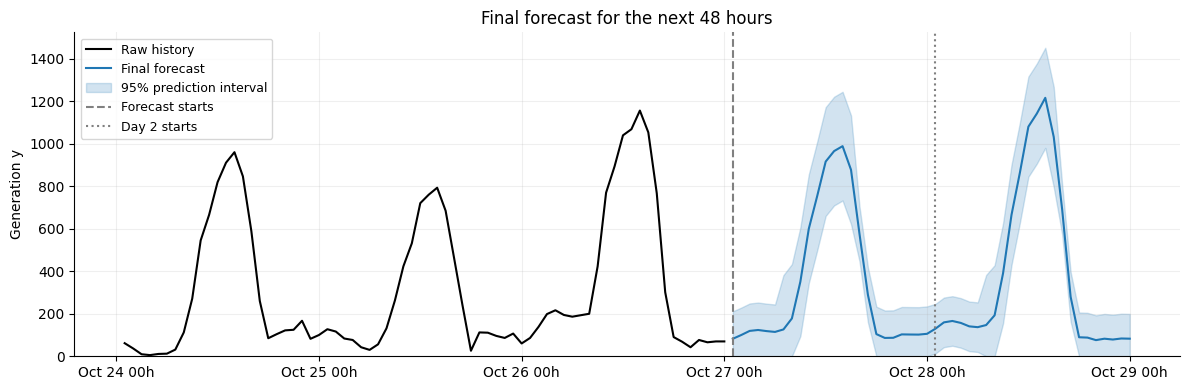

In [29]:
future_components = component_points(list(selected_recipe), [N])
point = blend_points(selected_recipe, future_components, [N])[N]
lower, upper = forecast_band(N, point, frozen_widths[selected_name])
submission = pd.DataFrame({'ds': future_weather.ds, 'forecast': point,
                           'lower_95': lower, 'upper_95': upper})

print('Submission model:', selected_name)
print('Weights: ' + ', '.join(f'{name}: {weight:.0%}' for name, weight in chosen_weights.items()))
display(submission)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(data.ds.iloc[-3 * DAY:], y[-3 * DAY:], color='black', label='Raw history')
ax.plot(submission.ds, submission.forecast, color='tab:blue', label='Final forecast')
ax.fill_between(submission.ds, submission.lower_95, submission.upper_95,
                color='tab:blue', alpha=0.2, label='95% prediction interval')
ax.axvline(submission.ds.iloc[0], color='grey', ls='--', label='Forecast starts')
ax.axvline(submission.ds.iloc[DAY], color='grey', ls=':', label='Day 2 starts')
ax.set(title='Final forecast for the next 48 hours', ylabel='Generation y', ylim=(0, None))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %Hh'))
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [30]:
assert len(submission) == H and submission.ds.is_unique
assert pd.DatetimeIndex(submission.ds).equals(expected_dates)
assert list(submission.columns) == ['ds', 'forecast', 'lower_95', 'upper_95']
assert np.isfinite(submission[['forecast', 'lower_95', 'upper_95']].to_numpy()).all()
assert submission.lower_95.ge(0).all()
assert submission.forecast.ge(submission.lower_95).all()
assert submission.upper_95.ge(submission.forecast).all()

csv_text = submission.to_csv(index=False)
output_path = ROOT / 'output/BARANIUK_project.csv'
output_path.parent.mkdir(exist_ok=True)
output_path.write_text(csv_text, encoding='utf-8')
print(f'Saved {len(submission)} rows on the kernel filesystem: {output_path}')
print('First forecast:', submission.ds.iloc[0], '| Last forecast:', submission.ds.iloc[-1])
print('Remote kernel: copy the CSV output below into a local BARANIUK_project.csv file.')
display({'text/plain': csv_text, 'text/csv': csv_text}, raw=True)


Saved 48 rows on the kernel filesystem: /content/time-series_energy-consumption/output/BARANIUK_project.csv
First forecast: 2026-10-27 01:00:00 | Last forecast: 2026-10-29 00:00:00
Remote kernel: copy the CSV output below into a local BARANIUK_project.csv file.


ds,forecast,lower_95,upper_95
2026-10-27 01:00:00,82.28186235396282,0.0,211.3696983867842
2026-10-27 02:00:00,99.99960764357567,0.0,229.08744367639704
2026-10-27 03:00:00,119.4091727253102,0.0,248.49700875813159
2026-10-27 04:00:00,123.69839186006467,0.0,252.78622789288605
2026-10-27 05:00:00,118.48498429926626,0.0,247.57282033208764
2026-10-27 06:00:00,114.63627779429665,0.0,243.724113827118
2026-10-27 07:00:00,126.31588601029708,0.0,382.0542752987461
2026-10-27 08:00:00,178.0720956842152,0.0,433.8104849726643
2026-10-27 09:00:00,350.5491632708908,94.81077398244173,606.2875525593399
2026-10-27 10:00:00,599.9182809364185,344.1798916479694,855.6566702248675
2026-10-27 11:00:00,754.7528989369316,499.01450964848254,1010.4912882253807
2026-10-27 12:00:00,916.324266476171,660.585877187722,1172.06265576462
2026-10-27 13:00:00,965.688567221088,709.9501779326389,1221.426956509537
2026-10-27 14:00:00,988.8100311064342,733.0716418179851,1244.5484203948831
2026-10-27 15:00:00,877.430171358214,621

**Before uploading:** inspect the selected model, holdout coverage and final curve above. Feature removal is an experiment and is not forced if CV prefers the full weather input. The exported three-model blend uses weights selected by the assignment's second-day objective, subject to each model receiving at least 10%.

**Limits:** observed weather makes historical results optimistic; the holdout was previously inspected; selection among several candidates on seven CV windows can overfit. Level-scaled intervals assume recent relative errors remain informative. A 95% label does not guarantee 95% realized coverage.

**LLM use:** an LLM assisted with the notebook code and explanations. The saved outputs show the selected weights and submission. Rerun sections 6–8 to regenerate the CSV. The earlier LightGBM candidate remains documented in `lightgbm_blend.ipynb`.